# Visualising Attention heads at different points during training: 



In [1]:
from transformers import AlbertForMaskedLM, AlbertConfig
from datasets import load_dataset
from rxnmapper.tokenization_smiles import SmilesTokenizer
import torch
import matplotlib.pyplot as plt

/home/sacharfd/miniconda3/envs/rxnmapper_v2/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Token and Model initialisations: 

- We are going to load the baseline RXNMapper V1:

In [2]:
# Define paths:
trained_model_path = "../rxnmapper/models/transformers/albert_heads_8_uspto_all_1310k"
vocab_path = "../rxnmapper/models/transformers/albert_heads_8_uspto_all_1310k/vocab.txt"

# Setup the tokenizer:
tokenizer = SmilesTokenizer(vocab_path)


def tokenize_function(examples):
    tokenized = tokenizer(examples["rxn"])
    return tokenized


# Setup model:
model = AlbertForMaskedLM.from_pretrained(
    trained_model_path,
    attn_implementation="sdpa",
)

Some weights of the model checkpoint at ../rxnmapper/models/transformers/albert_heads_8_uspto_all_1310k were not used when initializing AlbertForMaskedLM: ['albert.pooler.bias', 'albert.pooler.weight']
- This IS expected if you are initializing AlbertForMaskedLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing AlbertForMaskedLM from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


## Initialise the dataset: 

- Using Huggingface
- Extract a sample for visualisation: 

In [3]:
dataset_path = "../data/full_pretraining_data.csv"
dataset = load_dataset("csv", data_files=dataset_path)

# Tokenize the dataset:
dataset = dataset.map(tokenize_function, batched=True, num_proc=24)

# Forward pass:
example_idx = 10
example_sample = dataset["train"][example_idx]
input_ids = torch.tensor(example_sample["input_ids"]).unsqueeze(0)
attention_mask = torch.tensor(example_sample["attention_mask"]).unsqueeze(0)

Generating train split: 2853816 examples [00:01, 1485816.50 examples/s]
Map (num_proc=24): 100%|██████████| 2853816/2853816 [00:21<00:00, 132071.18 examples/s]


## Forward Pass: 

- Get the attention ouputs of the model

In [4]:
model.eval()
outputs = model(
    input_ids=input_ids,
    attention_mask=attention_mask,
    output_attentions=True,
)

AlbertSdpaAttention is used but `torch.nn.functional.scaled_dot_product_attention` does not support non-absolute `position_embedding_type` or `output_attentions=True` or `head_mask`. Falling back to the eager attention implementation, but specifying the eager implementation will be required from Transformers version v5.0.0 onwards. This warning can be removed using the argument `attn_implementation="eager"` when loading the model.
AlbertSdpaAttention is used but `torch.nn.functional.scaled_dot_product_attention` does not support non-absolute `position_embedding_type` or `output_attentions=True` or `head_mask`. Falling back to the eager attention implementation, but specifying the eager implementation will be required from Transformers version v5.0.0 onwards. This warning can be removed using the argument `attn_implementation="eager"` when loading the model.
AlbertSdpaAttention is used but `torch.nn.functional.scaled_dot_product_attention` does not support non-absolute `position_embeddi

## Plotting: 


- We know that for the V1 model, attention head of interest is in layer 10 (0-index). Lets see if we can spot it: 

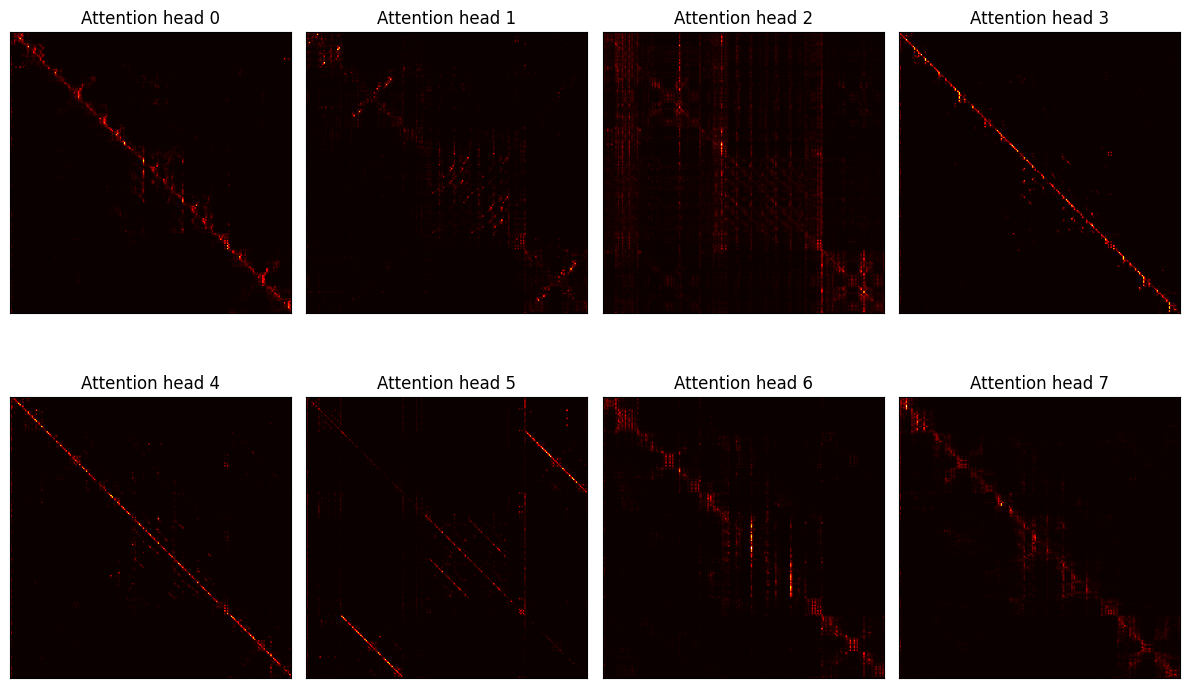

In [5]:
def plot_attn(attn, ax):
    """Simple plotting fn"""
    if torch.is_tensor(attn):
        attn = attn.detach().numpy()
    ax.imshow(
        attn,
        cmap="hot",
    )
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title("Attention head {}".format(i))


# Adapt which layer to visualize:
layer = 10

# Fix axis to show the 8 heads:
fig, axs = plt.subplots(2, 4, figsize=(12, 8))
axs = axs.flatten()

for i, ax in enumerate(axs):
    plot_attn(outputs.attentions[layer][0][i], ax)

plt.tight_layout()
plt.show()

#### Observation: 

We can spot how Head 5 (0-indexed) shows how products attend to reactants and vice versa.

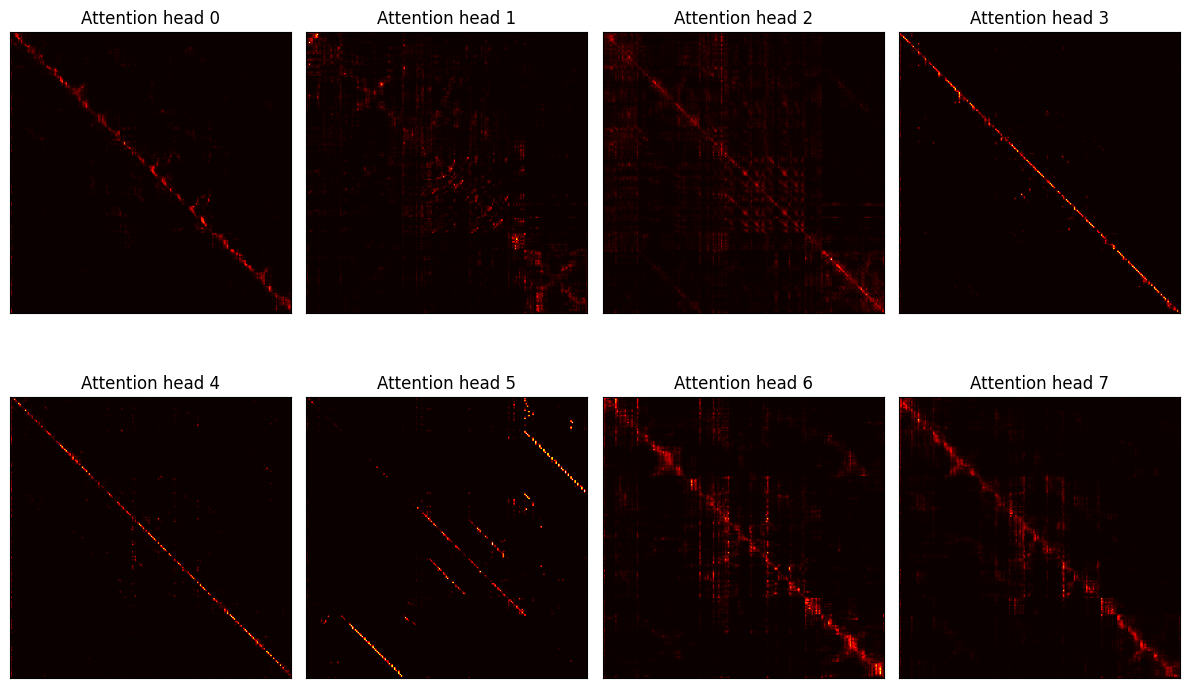

In [6]:
model_path = (
    "../trained_models/supervised_ft_Baseline_V1_with_attn_map/checkpoint-18900"
)
model = AlbertForMaskedLM.from_pretrained(
    model_path,
    attn_implementation="eager",
)

model.eval()
outputs = model(
    input_ids=input_ids,
    attention_mask=attention_mask,
    output_attentions=True,
)

# Adapt which layer to visualize:
layer = 10

# Fix axis to show the 8 heads:
fig, axs = plt.subplots(2, 4, figsize=(12, 8))
axs = axs.flatten()

for i, ax in enumerate(axs):
    plot_attn(outputs.attentions[layer][0][i], ax)

plt.tight_layout()
plt.show()